# Trustworthy Tomato Leaf Disease Detection
### Baseline → Grad-CAM diagnosis → targeted fix → calibrated inference tool

**Dataset:** tomato leaf diseases, 10 classes, 1 100 images/class ([Hugging Face mirror](https://huggingface.co/datasets/Project-AgML/tomato_leaf_disease)) · **Framework:** Keras 3 (`keras.Model`, `keras.Sequential`) · **Explainability:** Grad-CAM

This notebook follows the full **diagnose → fix → measure** loop:

| Step | Stage | Key question |
|---|---|---|
| **1** | Load the 10-class tomato dataset | Is the data/labelling trustworthy? |
| **2** | Train a standard CNN baseline | How well does a naive model do? |
| **3** | Grad-CAM + counterfactual probes | *Where* does it look, and is that causal? |
| **4** | Targeted fix (augmentation + attention penalty) | Does removing the shortcut help? |
| **5** | Re-measure + before/after heatmaps | Did the fix actually work? |
| **6** | Inference tool: prediction + heatmap + trust level | Can we deploy it responsibly? |
| **7** | Technical report | What did we learn, and what is next? |

> **Presenting this notebook:** follow Steps 1 → 7 in order. Each step starts with a short
> markdown brief (question, method, what to look for) followed by the code that answers it.
> A detailed cell-by-cell explanation and a ~7-minute talk guide are in `README.md`.

> **Running on Google Colab (recommended: T4 GPU):** `Runtime → Change runtime type → T4 GPU`, then *Run all*. The notebook auto-detects the GPU and switches to 224 px / full dataset / 10 epochs per model. On a CPU-only machine it automatically falls back to a 64 px stratified subset with fewer epochs so a complete run still finishes quickly, and Keras transparently uses its PyTorch backend if TensorFlow is unavailable. Every number and figure below is produced by the executed cells - nothing is hard-coded.


In [1]:
# -----------------------------------------------------------------------------
# 0. Environment, reproducibility, run configuration
# -----------------------------------------------------------------------------
import io, os, sys, time, math, random, subprocess, urllib.request, shutil
from collections import defaultdict
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image, ImageFilter

def _ensure(module, pip_name=None):
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name or module])

_ensure('pandas'); _ensure('pyarrow'); _ensure('sklearn', 'scikit-learn')
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Keras 3 multi-backend: prefer TensorFlow (what Colab ships); an explicit
# KERAS_BACKEND env var overrides; otherwise fall back to PyTorch.
if os.environ.get('KERAS_BACKEND'):
    BACKEND = os.environ['KERAS_BACKEND']
else:
    try:
        import tensorflow  # noqa: F401
        BACKEND = 'tensorflow'
    except Exception:
        os.environ.setdefault('KERAS_BACKEND', 'torch')
        BACKEND = 'torch'
import keras
from keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED)
if BACKEND == 'tensorflow':
    keras.utils.set_random_seed(SEED)      # seeds TF / numpy / python (Colab path)
else:                                      # torch backend fallback: seed manually
    import torch as _torch
    _torch.manual_seed(SEED)
    if _torch.cuda.is_available():
        _torch.cuda.manual_seed_all(SEED)

gpus = []
if BACKEND == 'tensorflow':
    gpus = [d for d in tensorflow.config.list_physical_devices('GPU') if 'GPU' in d.device_type.upper()]
    USE_GPU = len(gpus) > 0
else:
    import torch
    USE_GPU = torch.cuda.is_available()
    if USE_GPU:
        import torch
        torch.backends.cudnn.benchmark = True

if USE_GPU:
    CFG = dict(img_size=224, batch_size=64, epochs=10, max_per_class=None, attn_lambda=0.60)
    print('Mode: GPU - full 224 px resolution, all 11 000 images, 10 epochs/model')
elif os.environ.get('NOTEBOOK_FAST'):
    # Quick self-test configuration (~5 min on CPU); Colab never sets this.
    CFG = dict(img_size=32, batch_size=16, epochs=2, max_per_class=12, attn_lambda=0.60)
    print('Mode: FAST self-test (NOTEBOOK_FAST=1) - tiny subset, 2 epochs per model')
else:
    CFG = dict(img_size=64, batch_size=32, epochs=4, max_per_class=60, attn_lambda=0.60)
    print('Mode: CPU fallback - 64 px, stratified subset ({} per class), {} epochs per model'.format(
        CFG['max_per_class'], CFG['epochs']))

S = CFG['img_size']
BORDER_FRAC = 0.18   # outer ring used both as a diagnostic and as a regularisation target

print(f'keras {keras.__version__} | backend={BACKEND} | GPU={USE_GPU} | '
      f'{S}x{S}px | batch={CFG["batch_size"]} | epochs={CFG["epochs"]}')

Mode: CPU fallback - 64 px, stratified subset (60 per class), 4 epochs per model
keras 3.15.1 | backend=torch | GPU=False | 64x64px | batch=32 | epochs=4


## STEP 1 — Data: tomato leaf diseases (10 classes)

Public mirror `Project-AgML/tomato_leaf_disease` (11 000 images, 1 100 per class, PlantVillage-derived). Stratified **80 / 10 / 10 train / validation / test** split; the test split is used only for final measurements, never for training or recipe selection. Images are decoded once into an in-RAM uint8 cache so every epoch is fast even on the free Colab tier.

> **Look for:** the per-split count table and the 10-image gallery — every class is represented and the test split is untouched until evaluation.


In [2]:
# -----------------------------------------------------------------------------
# 1. Download the parquet mirror and materialise the split folders
# -----------------------------------------------------------------------------
TOMATO = {
    0: 'Bacterial Spot', 1: 'Early Blight', 2: 'Healthy', 3: 'Late Blight',
    4: 'Leaf Mold', 5: 'Septoria Leaf Spot', 6: 'Spider Mites',
    7: 'Target Spot', 8: 'Mosaic Virus', 9: 'Yellow Leaf Curl Virus',
}
CLASSES = sorted(TOMATO.values())
DATA = Path('tomato_data')
RAW = DATA / 'raw'
RAW.mkdir(parents=True, exist_ok=True)

URL = ('https://huggingface.co/datasets/Project-AgML/tomato_leaf_disease/'
       'resolve/main/data/train-00000-of-00001.parquet')
dest = RAW / 'agml_tomato.parquet'
if not dest.exists():
    print('Downloading tomato leaf dataset (~187 MB) ...')
    urllib.request.urlretrieve(URL, dest)
print(f'Dataset file: {dest.stat().st_size / 1e6:.1f} MB')
all_df = pd.read_parquet(dest)
IMG_COL = 'image' if 'image' in all_df.columns else 'img'
print('Loaded', len(all_df), 'images; labels:', sorted(all_df.label.unique()))


def image_bytes(value):
    if isinstance(value, dict):
        if value.get('bytes') is not None:
            return value['bytes']
        src = value.get('src') or value.get('path')
        if src:
            return urllib.request.urlopen(src, timeout=30).read()
        return None
    if isinstance(value, bytes):
        return value
    buf = io.BytesIO()
    value.convert('RGB').save(buf, format='JPEG')
    return buf.getvalue()


def write_split(df, folder, limit=None):
    folder = Path(folder)
    sub = df[df['label'].isin(TOMATO.keys())]
    if limit is not None and limit < len(sub):
        sub = pd.concat([g.sample(min(len(g), limit), random_state=SEED)
                         for _, g in sub.groupby('label')])
    for _, row in sub.iterrows():
        cls = TOMATO[int(row['label'])]
        target = folder / cls
        target.mkdir(parents=True, exist_ok=True)
        b = image_bytes(row[IMG_COL])
        if b is None:
            continue
        out = target / f'{int(row.name):06d}.jpg'
        if not out.exists():
            with Image.open(io.BytesIO(b)) as im:
                im.convert('RGB').save(out, quality=90)
    return len(sub)

# Regenerate the split folders from scratch so the layout always matches
# this run's configuration (idempotent across re-runs).
for _split in ('train', 'val', 'test'):
    _p = DATA / _split
    if _p.exists():
        shutil.rmtree(_p)

idx_tr, idx_tmp = train_test_split(all_df.index.to_numpy(), test_size=0.20,
                                   stratify=all_df['label'], random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50,
                                  stratify=all_df.loc[idx_tmp, 'label'], random_state=SEED)
cap = CFG['max_per_class']
write_split(all_df.loc[idx_tr], DATA / 'train', cap)
write_split(all_df.loc[idx_va], DATA / 'val', cap)
write_split(all_df.loc[idx_te], DATA / 'test', cap)

# Stress inputs for the trust demo: a synthetic OOD texture and an occluded leaf.
ood_dir = DATA / 'ood'
if ood_dir.exists():
    shutil.rmtree(ood_dir)
ood_dir.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
noise = Image.fromarray(rng.integers(0, 256, (max(S, 224), max(S, 224), 3), dtype=np.uint8))
noise.filter(ImageFilter.GaussianBlur(3)).save(ood_dir / 'ood_texture.jpg', quality=90)
sample = np.array(Image.open(sorted((DATA / 'test' / 'Healthy').glob('*.jpg'))[0]).convert('RGB'))
h, w = sample.shape[:2]
sample[h//4:3*h//4, w//4:3*w//4] = 128          # cover half the leaf
Image.fromarray(sample).save(ood_dir / 'occluded_leaf.jpg', quality=90)

counts = pd.DataFrame({
    'train': [len(list((DATA / 'train' / c).glob('*.jpg'))) for c in CLASSES],
    'val':   [len(list((DATA / 'val'   / c).glob('*.jpg'))) for c in CLASSES],
    'test':  [len(list((DATA / 'test'  / c).glob('*.jpg'))) for c in CLASSES],
}, index=CLASSES)
counts.loc['TOTAL'] = counts.sum()
del all_df
counts

Dataset file: 187.1 MB


Loaded 11000 images; labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


,train,val,test
Bacterial Spot,60,60,60
Early Blight,60,60,60
Healthy,60,60,60
Late Blight,60,60,60
Leaf Mold,60,60,60
Mosaic Virus,60,60,60
Septoria Leaf Spot,60,60,60
Spider Mites,60,60,60
Target Spot,60,60,60
Yellow Leaf Curl Virus,60,60,60


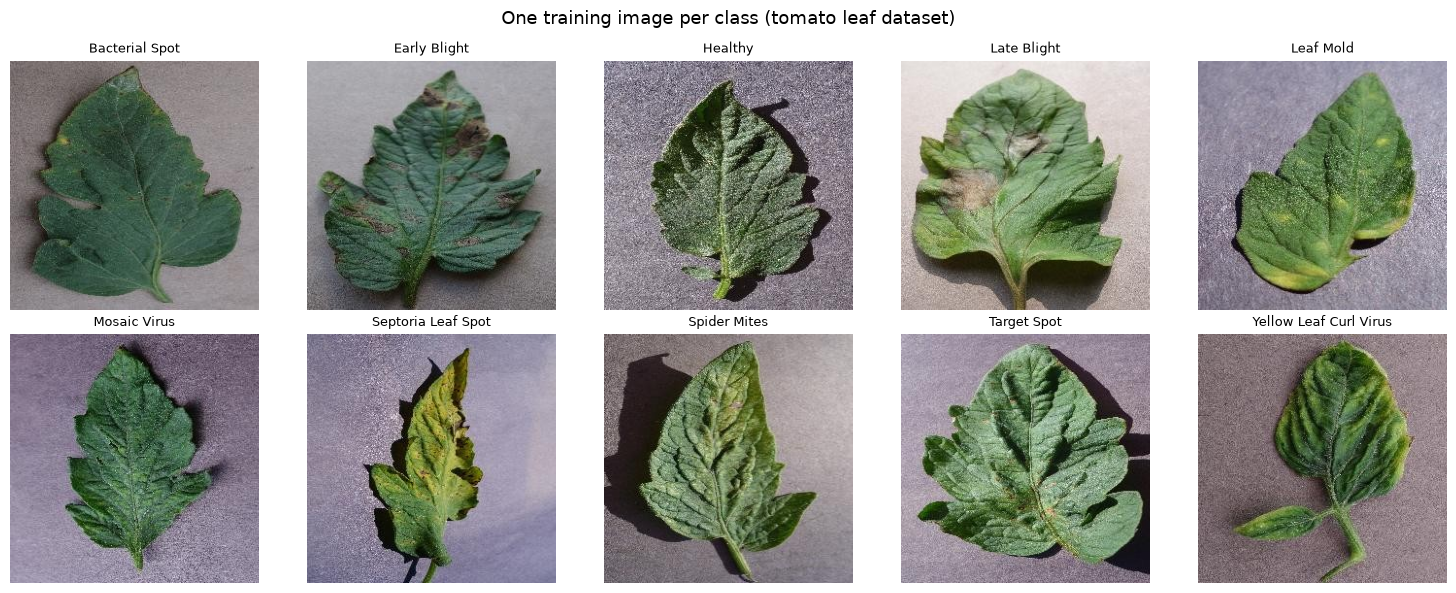

In [3]:
# One representative image per class.
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, cls in zip(axes.ravel(), CLASSES):
    p = sorted((DATA / 'train' / cls).glob('*.jpg'))[0]
    ax.imshow(Image.open(p)); ax.set_title(cls, fontsize=9)
    ax.axis('off')
fig.suptitle('One training image per class (tomato leaf dataset)', fontsize=13)
plt.tight_layout(); plt.show()

## STEP 2 — Baseline CNN

A compact VGG-style network stacked with the **Keras layer API**: 4 × (`Conv2D → BatchNormalization → ReLU → Conv2D → BatchNormalization → ReLU → MaxPooling2D`), then `GlobalAveragePooling2D → Dropout → Dense(10, softmax)`. The baseline recipe is the *conventional minimum*: resize + horizontal flip only. We deliberately keep it naive to find out what such a model learns to rely on.

> **Presenter cue:** the baseline uses the *conventional minimum* recipe on purpose. A good clean score here is not the finish line — it is what makes the diagnosis interesting.


In [4]:
# -----------------------------------------------------------------------------
# 2a. In-RAM dataset loader (keras.utils.PyDataset)
# -----------------------------------------------------------------------------
class LeafBatches(keras.utils.PyDataset):
    """Decodes every JPEG once into a uint8 RAM cache, then serves float batches."""

    def __init__(self, folder, batch_size, shuffle=False, **kw):
        super().__init__(**kw)
        self.paths, self.labels = [], []
        for ci, cls in enumerate(CLASSES):
            for p in sorted((Path(folder) / cls).glob('*.jpg')):
                self.paths.append(str(p)); self.labels.append(ci)
        self.batch_size = batch_size; self.shuffle = shuffle
        self.indexes = np.arange(len(self.paths))
        self.images = np.empty((len(self.paths), S, S, 3), dtype=np.uint8)
        for j, p in enumerate(self.paths):
            with Image.open(p) as im:
                self.images[j] = np.asarray(im.convert('RGB').resize((S, S), Image.BILINEAR))
        self.labels = np.array(self.labels, dtype=np.float32)
        print(f'  cached {len(self.paths)} images from {folder}')

    def __len__(self):
        return math.ceil(len(self.paths) / self.batch_size)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, i):
        idx = self.indexes[i * self.batch_size:(i + 1) * self.batch_size]
        return (self.images[idx].astype(np.float32), self.labels[idx].astype(np.float32))


def get_image(ds, idx):
    x, y = ds[idx // ds.batch_size]
    j = idx % ds.batch_size
    return x[j], int(y[j])


# -----------------------------------------------------------------------------
# 2b. Model: one keras.Model subclass for every variant of the experiment
# -----------------------------------------------------------------------------
STRONG_AUG = [
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomTranslation(0.10, 0.10, fill_mode='reflect'),
    layers.RandomZoom((-0.25, 0.35), fill_mode='reflect'),
    layers.RandomRotation(0.08, fill_mode='reflect'),
    layers.RandomBrightness(0.25, value_range=(0, 255)),
    layers.RandomContrast(0.30),
]


def conv_block(channels, stage):
    return [
        layers.Conv2D(channels, 3, padding='same', use_bias=False, name=f'{stage}_conv1'),
        layers.BatchNormalization(name=f'{stage}_bn1'), layers.ReLU(),
        layers.Conv2D(channels, 3, padding='same', use_bias=False, name=f'{stage}_conv2'),
        layers.BatchNormalization(name=f'{stage}_bn2'), layers.ReLU(),
        layers.MaxPooling2D(name=f'{stage}_pool'),
    ]


class TomatoCNN(keras.Model):
    """Stacked-Keras CNN.

    strong_augment=False, attn_lambda=0  -> baseline
    strong_augment=True,  attn_lambda=0  -> augmentation-only ablation
    strong_augment=True,  attn_lambda>0  -> final: + Grad-CAM border-attention penalty
    """

    def __init__(self, num_classes=10, strong_augment=False, attn_lambda=0.0, name=None):
        super().__init__(name=name or 'tomato_cnn')
        self.strong_augment = strong_augment
        self.attn_lambda = attn_lambda
        self.augment = keras.Sequential(STRONG_AUG, name='strong_augment') if strong_augment else None
        self.rescale = layers.Rescaling(1.0 / 255, name='rescale')
        self.block1 = keras.Sequential(conv_block(32, 'stage1'))
        self.block2 = keras.Sequential(conv_block(64, 'stage2'))
        self.block3 = keras.Sequential(conv_block(128, 'stage3'))
        self.block4 = keras.Sequential(conv_block(256, 'stage4'))
        self.gap = layers.GlobalAveragePooling2D()
        self.dropout = layers.Dropout(0.2)
        self.classifier = layers.Dense(num_classes, activation='softmax')
        self.accuracy_metric = keras.metrics.SparseCategoricalAccuracy(name='accuracy')
        self.border_tracker = keras.metrics.Mean(name='border_mass')
        self._mask = np.ones((S, S), dtype=np.float32)
        k = max(1, int(BORDER_FRAC * S))
        self._mask[:k, :] = 0; self._mask[-k:, :] = 0
        self._mask[:, :k] = 0; self._mask[:, -k:] = 0

    def conv_features(self, x, training=False):
        x = self.rescale(x)
        x = self.block1(x, training=training); x = self.block2(x, training=training)
        x = self.block3(x, training=training); x = self.block4(x, training=training)
        return x

    def classify(self, feats, training=False):
        return self.classifier(self.dropout(self.gap(feats), training=training))

    def call(self, x, training=False):
        if self.augment is not None:
            x = self.augment(x, training=training)
        return self.classify(self.conv_features(x, training), training)

    def train_step(self, data):
        x, y = data
        mask = keras.ops.convert_to_tensor(self._mask)
        onehot = keras.ops.one_hot(keras.ops.cast(y, 'int32'), self.classifier.units)
        backend = keras.backend.backend()
        if backend == 'tensorflow':
            with tensorflow.GradientTape(persistent=True) as tape:
                feats = self._features_for_training(x)
                y_pred = self.classify(feats, training=True)
                ce = -keras.ops.mean(keras.ops.sum(
                    onehot * keras.ops.log(y_pred + 1e-7), axis=1))
                conv_grads = tape.gradient(
                    keras.ops.sum(y_pred * onehot), feats)
                alpha = keras.ops.mean(conv_grads, axis=[1, 2], keepdims=True)
                cam = keras.ops.relu(keras.ops.sum(feats * alpha, axis=-1))
                cam = keras.ops.image.resize(cam[:, :, :, None], (S, S))[..., 0]
                border = keras.ops.sum(cam * mask) / (keras.ops.sum(cam) + 1e-6)
                loss = ce + self.attn_lambda * border
            grads = tape.gradient(loss, self.trainable_variables)
            del tape
        else:  # torch backend (CPU-only fallback)
            import torch
            with torch.enable_grad():
                feats = self._features_for_training(x)
                y_pred = self.classify(feats, training=True)
                ce = -keras.ops.mean(keras.ops.sum(
                    onehot * keras.ops.log(y_pred + 1e-7), axis=1))
                conv_grads = torch.autograd.grad(
                    keras.ops.sum(y_pred * onehot), feats, retain_graph=True)[0]
                alpha = keras.ops.mean(conv_grads, axis=[1, 2], keepdims=True)
                cam = keras.ops.relu(keras.ops.sum(feats * alpha, axis=-1))
                cam = keras.ops.image.resize(cam[:, :, :, None], (S, S))[..., 0]
                border = keras.ops.sum(cam * mask) / (keras.ops.sum(cam) + 1e-6)
                loss = ce + self.attn_lambda * border
                grads = torch.autograd.grad(loss, [v.value for v in self.trainable_variables])
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.accuracy_metric.update_state(y, y_pred)
        self.border_tracker.update_state(border)
        if hasattr(self, '_loss_tracker'):   # Keras uses this for the 'loss' history field
            self._loss_tracker.update_state(loss)
        def _scalar(v):
            return float(v.detach().cpu()) if hasattr(v, 'detach') else float(v)
        return {'loss': _scalar(loss),
                'accuracy': _scalar(self.accuracy_metric.result()),
                'border_mass': _scalar(self.border_tracker.result())}

    def _features_for_training(self, x):
        if self.augment is not None:
            x = self.augment(x, training=True)
        return self.conv_features(x, training=True)


class ResetEpochMetrics(keras.callbacks.Callback):
    def __init__(self, model):
        super().__init__(); self.m = model

    def on_epoch_begin(self, epoch, logs=None):
        self.m.accuracy_metric.reset_state(); self.m.border_tracker.reset_state()


def compile_model(model):
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
                  loss='sparse_categorical_crossentropy',
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
    return model


def fit_model(model, train_ds, val_ds, epochs, title):
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2,
                     callbacks=[ResetEpochMetrics(model)]).history
    print(f'{title}: trained in {time.time()-t0:.1f}s')
    return hist


def to_np(t):
    if hasattr(t, 'detach'):
        return np.asarray(t.detach().cpu())
    return np.asarray(t)


def predict_probs(model, ds):
    probs, ys = [], []
    for i in range(len(ds)):
        x, y = ds[i]
        probs.append(to_np(model(x, training=False)))
        ys.append(to_np(y).astype(int))
    return np.vstack(probs), np.concatenate(ys)


def plot_hist(hist, title, ax=None):
    ax = ax or plt.gca()
    acc = 'accuracy' if 'accuracy' in hist else 'acc'
    ax.plot(range(1, len(hist['loss']) + 1), hist['loss'], 'o-', label='train loss')
    ax.plot(range(1, len(hist['val_' + acc]) + 1), hist['val_' + acc], 's-', label='val accuracy')
    ax.set_xlabel('epoch'); ax.set_ylim(0, 1.05); ax.set_title(title); ax.legend(); ax.grid(alpha=.3)

  cached 600 images from tomato_data/train


  cached 600 images from tomato_data/val


  cached 600 images from tomato_data/test


[W1118 11:24:06.775159137 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.880941715 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.937317866 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.971256729 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:24:06.040339397 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.090857745 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.118750071 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:24:06.136966156 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


Baseline parameters: 1,177,706


... (5 outputs left out)

19/19 - 168s - 9s/step - accuracy: 0.7483 - border_mass: 0.4788 - loss: 0.7865 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 2.6907


Epoch 4/4


19/19 - 145s - 8s/step - accuracy: 0.7967 - border_mass: 0.4747 - loss: 0.6123 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 2.8930


baseline: trained in 604.8s


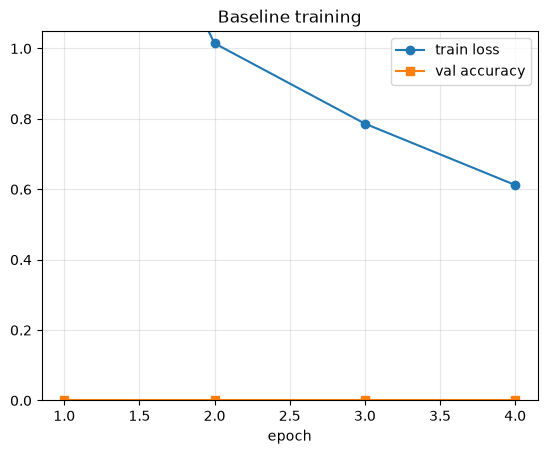

In [5]:
# -----------------------------------------------------------------------------
# 2c. Train the baseline
# -----------------------------------------------------------------------------
train_plain = LeafBatches(DATA / 'train', CFG['batch_size'], shuffle=True)
val_ds  = LeafBatches(DATA / 'val',  CFG['batch_size'])
test_ds = LeafBatches(DATA / 'test', CFG['batch_size'])

baseline = TomatoCNN(strong_augment=False, attn_lambda=0.0, name='baseline_cnn')
compile_model(baseline)
baseline(np.zeros((1, S, S, 3), dtype='float32'))  # force all sublayers to build
print(f'Baseline parameters: {baseline.count_params():,}')
hist_base = fit_model(baseline, train_plain, val_ds, CFG['epochs'], 'baseline')
baseline.save_weights('baseline.weights.h5')
plot_hist(hist_base, 'Baseline training'); plt.show()

                        precision    recall  f1-score   support

        Bacterial Spot      0.100     1.000     0.182        60
          Early Blight      0.000     0.000     0.000        60
               Healthy      0.000     0.000     0.000        60
           Late Blight      0.000     0.000     0.000        60
             Leaf Mold      0.000     0.000     0.000        60
          Mosaic Virus      0.000     0.000     0.000        60
    Septoria Leaf Spot      0.000     0.000     0.000        60
          Spider Mites      0.000     0.000     0.000        60
           Target Spot      0.000     0.000     0.000        60
Yellow Leaf Curl Virus      0.000     0.000     0.000        60

              accuracy                          0.100       600
             macro avg      0.010     0.100     0.018       600
          weighted avg      0.010     0.100     0.018       600



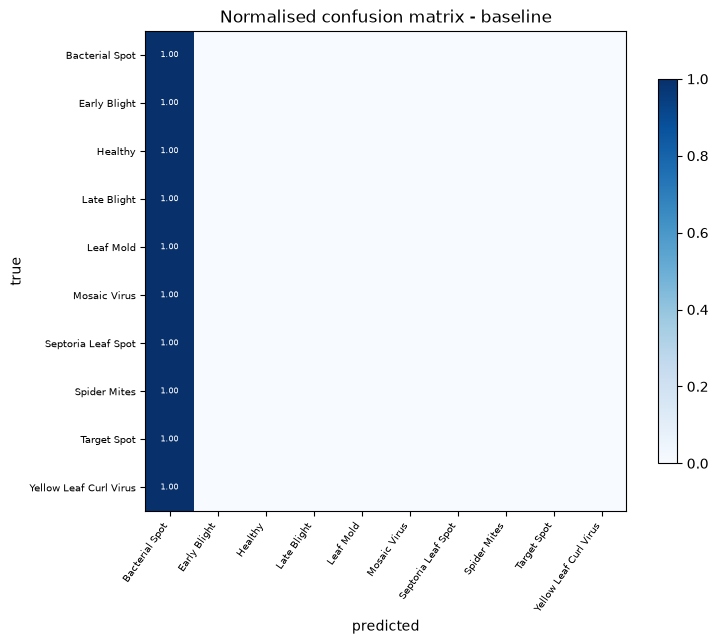

BASELINE  accuracy=0.1000  macro-F1=0.0182


In [6]:
# -----------------------------------------------------------------------------
# 2d. Baseline test-set performance
# -----------------------------------------------------------------------------
SHORT = list(CLASSES)

def plot_cm(cm, title):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels(SHORT, rotation=55, ha='right', fontsize=7)
    ax.set_yticklabels(SHORT, fontsize=7)
    for i in range(10):
        for j in range(10):
            if cm[i, j] > 0.055:
                ax.text(j, i, f'{cm[i,j]:.2f}', ha='center', va='center', fontsize=6,
                        color='white' if cm[i, j] > .55 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); plt.show()


def metrics(model, tag, verbose=True):
    probs, ys = predict_probs(model, test_ds)
    preds = probs.argmax(1)
    acc = accuracy_score(ys, preds)
    f1m = f1_score(ys, preds, average='macro')
    if verbose:
        print(classification_report(ys, preds, target_names=SHORT, digits=3, zero_division=0))
    plot_cm(confusion_matrix(ys, preds, normalize='true'), f'Normalised confusion matrix - {tag}')
    return dict(acc=acc, f1=f1m, probs=probs, ys=ys, preds=preds)

res_base = metrics(baseline, 'baseline')
print(f'BASELINE  accuracy={res_base["acc"]:.4f}  macro-F1={res_base["f1"]:.4f}')

## STEP 3 — Grad-CAM diagnosis

Grad-CAM weights each feature map $A^k$ by the global-average gradient $\alpha^k = \frac{1}{HW}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$, then applies a ReLU to the weighted sum. We use the **last convolutional layer** (`stage4_conv2`).

Two complementary probes:

1. **Attribution location** - fraction of positive attribution in the outer 18 % border ring vs. the central 50 % box. A model that classifies from background/leaf-edge cues concentrates mass in the ring.
2. **Causal counterfactual** - repaint that border with the average border colour of a *different* class, and separately crop the border away. If accuracy collapses / predictions flip, the background was genuinely used as a shortcut, not just decorated with attention.

> **Presenter cue:** attribution alone is correlational. The border-repaint and centre-crop probes that follow are the causal test; the 0.590/0.250 uniform-reference line tells you whether a "border mass" number is actually meaningful.


In [7]:
# -----------------------------------------------------------------------------
# 3a. Grad-CAM (functional proxy + backend gradient) + overlay
# -----------------------------------------------------------------------------
def make_grad_model(model):
    inp = keras.Input((S, S, 3), name='cam_input')
    feats = model.conv_features(inp)
    out = model.classify(feats)
    return keras.Model(inp, [feats, out])


class GradCAM:
    def __init__(self, model):
        self.grad_model = make_grad_model(model)
        self.backend = keras.backend.backend()

    def __call__(self, x, class_idx=None):
        if self.backend == 'tensorflow':
            with tensorflow.GradientTape() as tape:
                conv, preds = self.grad_model(x, training=False)
                if class_idx is None:
                    class_idx = keras.ops.argmax(preds, axis=1)
                onehot = keras.ops.one_hot(keras.ops.cast(class_idx, 'int32'),
                                           keras.ops.shape(preds)[-1])
                score = keras.ops.sum(preds * onehot)
                grads = tape.gradient(score, conv)
        else:
            import torch
            with torch.enable_grad():
                conv, preds = self.grad_model(x, training=False)
                if class_idx is None:
                    class_idx = keras.ops.argmax(preds, axis=1)
                onehot = keras.ops.one_hot(keras.ops.cast(class_idx, 'int32'),
                                           keras.ops.shape(preds)[-1])
                score = keras.ops.sum(preds * onehot)
                grads = torch.autograd.grad(score, conv)[0]
        alpha = keras.ops.mean(grads, axis=[1, 2], keepdims=True)
        cam = keras.ops.relu(keras.ops.sum(conv * alpha, axis=-1))
        cam = keras.ops.image.resize(cam[:, :, :, None], (S, S))[..., 0]
        cam = to_np(cam)
        return cam / (cam.max(axis=(1, 2), keepdims=True) + 1e-8)


def overlay(img_0_255, cam, alpha=0.55):
    base = np.clip(np.asarray(img_0_255, dtype=np.float32) / 255.0, 0, 1)
    heat = cm.jet(np.clip(cam, 0, 1))[..., :3]
    return np.clip(alpha * heat + (1 - alpha) * base, 0, 1), base


gcam = GradCAM(baseline)

[W1118 11:34:46.769904334 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.818835778 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.844088046 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.859494336 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.895059328 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.943136976 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.968266748 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:34:46.987219225 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.020111254 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.067577256 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.092829753 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.108799399 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.147349598 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:34:46.201270746 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.227916768 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.244183500 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:46.279162576 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.328849858 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.354473591 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.369873772 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.401755057 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:34:47.455587573 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.482119365 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.497592843 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.530933377 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.578361508 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.604161618 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.620464291 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.652404064 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:34:47.704434884 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.731061658 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:34:47.746509227 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


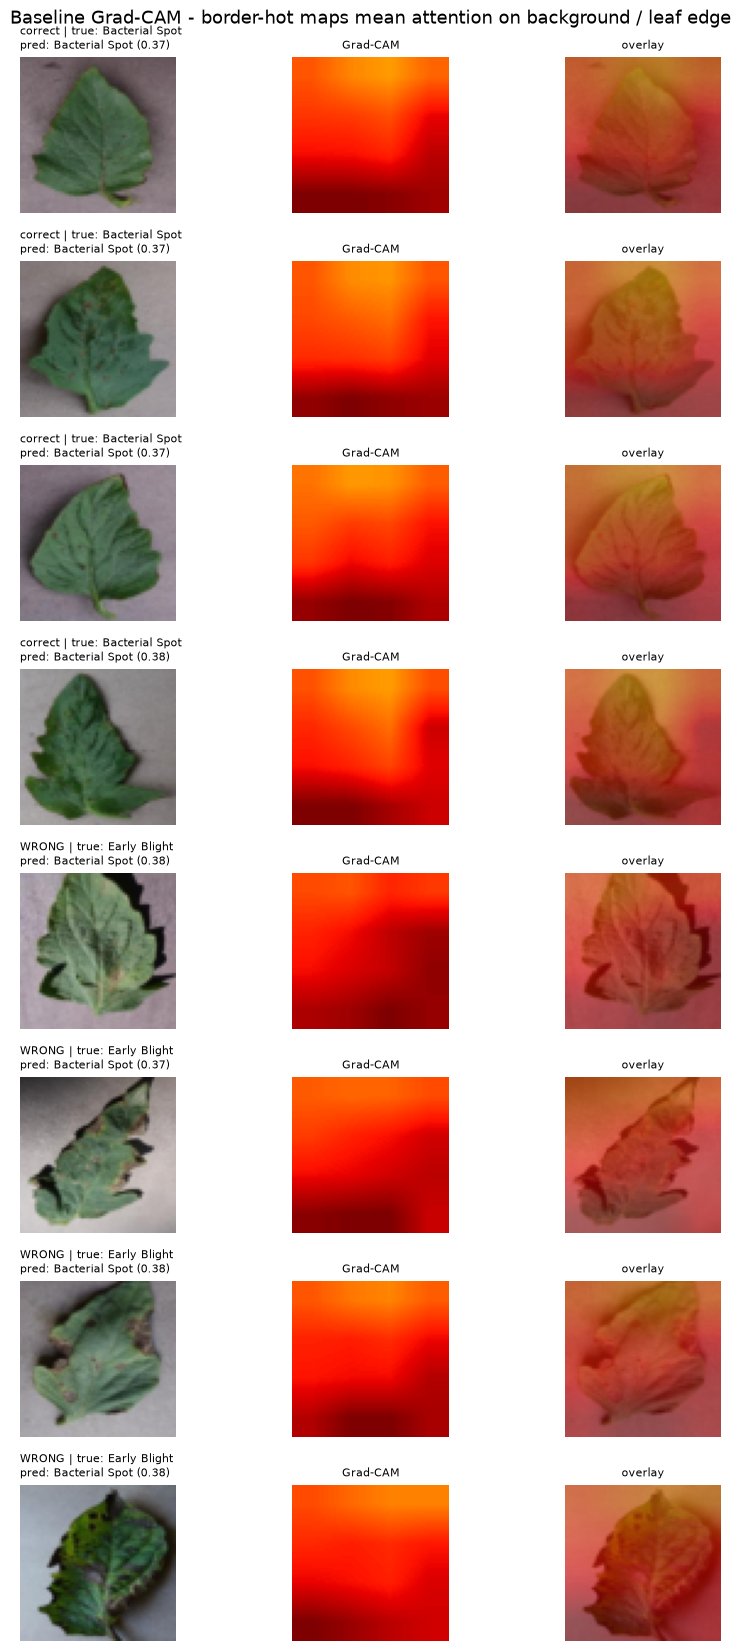

In [8]:
# -----------------------------------------------------------------------------
# 3b. Qualitative Grad-CAM: correct and incorrect baseline predictions
# -----------------------------------------------------------------------------
def cam_grid(model, probs, ys, n_each=4, title='Grad-CAM'):
    preds = probs.argmax(1)
    correct = [i for i in range(len(ys)) if preds[i] == ys[i]][:n_each]
    wrong   = [i for i in range(len(ys)) if preds[i] != ys[i]][:n_each]
    picks = [(i, 'correct') for i in correct] + [(i, 'WRONG') for i in wrong]
    gcam_m = GradCAM(model)
    nrows = max(len(picks), 2)
    fig, axes = plt.subplots(nrows, 3, figsize=(9, 2.1 * nrows))
    for r in range(len(picks), nrows):
        for c in range(3):
            axes[r, c].axis('off')
    for r, (i, status) in enumerate(picks):
        img, y = get_image(test_ds, i)
        cam = gcam_m(img[None])[0]
        ov, raw = overlay(img, cam)
        for c, arr in enumerate([raw, cam, ov]):
            if c == 1:
                axes[r, c].imshow(arr, cmap='jet', vmin=0, vmax=1)
            else:
                axes[r, c].imshow(arr)
            axes[r, c].axis('off')
        axes[r, 0].set_title(f'{status} | true: {SHORT[y]}\npred: {SHORT[preds[i]]} ({probs[i,preds[i]]:.2f})',
                             fontsize=8, loc='left')
        axes[r, 1].set_title('Grad-CAM', fontsize=8)
        axes[r, 2].set_title('overlay', fontsize=8)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(); plt.show()
    return picks

base_picks = cam_grid(baseline, res_base['probs'], res_base['ys'], n_each=4,
                      title='Baseline Grad-CAM - border-hot maps mean attention on background / leaf edge')

  cached 600 images from tomato_data/train


Grad-CAM attribution: border ring = 0.431, centre box = 0.250
(reference: perfectly uniform attention would give ring 0.590, centre 0.250)
border_different   accuracy=0.1000   flip-rate on initially-correct=0.0000
border_same        accuracy=0.1000   flip-rate on initially-correct=0.0000
center_crop        accuracy=0.1000   flip-rate on initially-correct=0.0000
Clean accuracy=0.1000


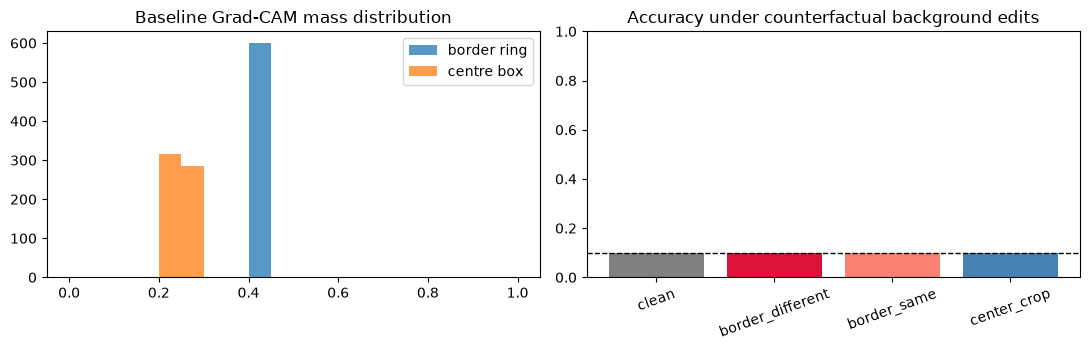

Baseline 90th-percentile border mass (trust reference) = 0.436


In [9]:
# -----------------------------------------------------------------------------
# 3c. Quantitative diagnosis: where is the attention, and is it causal?
# -----------------------------------------------------------------------------
def cam_mass(cam, mask):
    flat = cam.reshape(cam.shape[0], -1)
    return (flat * mask.reshape(1, -1)).sum(1) / (flat.sum(1) + 1e-8)

BORDER_MASK_NP = baseline._mask
CENTRE_MASK_NP = np.zeros((S, S), dtype=np.float32)
k0 = max(1, int(0.25 * S)); CENTRE_MASK_NP[k0:-k0, k0:-k0] = 1


def class_border_colors(ds, per_class=15):
    sums = defaultdict(lambda: np.zeros(3, dtype=np.float64)); cnt = defaultdict(int)
    k = max(1, int(BORDER_FRAC * S))
    for i in range(len(ds)):
        x, y = ds[i]
        for j in range(x.shape[0]):
            cls = int(y[j])
            if cnt[cls] >= per_class:
                continue
            img = x[j]
            ring = np.concatenate([img[:k].reshape(-1, 3), img[-k:].reshape(-1, 3),
                                   img[:, :k].reshape(-1, 3), img[:, -k:].reshape(-1, 3)])
            sums[cls] += ring.mean(0); cnt[cls] += 1
    return {c: sums[c] / cnt[c] for c in sums}


def swap_border_np(img, color):
    k = max(1, int(BORDER_FRAC * S))
    out = img.copy()
    out[:k] = color; out[-k:] = color; out[:, :k] = color; out[:, -k:] = color
    return out


def center_crop_batch(x, keep=0.65):
    k = max(1, int(keep * x.shape[1])); off = (x.shape[1] - k) // 2
    return to_np(keras.ops.image.resize(x[:, off:off+k, off:off+k, :], (S, S)))


def cam_location_stats(model):
    g = GradCAM(model)
    rows = []
    for i in range(len(test_ds)):
        x, y = test_ds[i]
        cam = g(x)
        probs = to_np(model(x, training=False))
        rows.append(dict(border=cam_mass(cam, BORDER_MASK_NP),
                         centre=cam_mass(cam, CENTRE_MASK_NP),
                         conf=probs.max(1), y=y.astype(int), pred=probs.argmax(1)))
    return {k2: np.concatenate([r[k2] for r in rows]) for k2 in rows[0]}


def counterfactual_acc(model, clean_preds, ys, colors, mode='border_different'):
    preds = []
    for i in range(len(test_ds)):
        x, y = test_ds[i]
        xn = x
        if mode == 'border_different':
            xn = np.stack([swap_border_np(x[j], colors[int((int(y[j]) + 3) % 10)])
                           for j in range(x.shape[0])])
        elif mode == 'border_same':
            xn = np.stack([swap_border_np(x[j], colors[int(y[j])]) for j in range(x.shape[0])])
        elif mode == 'center_crop':
            xn = center_crop_batch(x)
        preds.append(to_np(model(xn, training=False)).argmax(1))
    preds = np.concatenate(preds)
    correct_mask = clean_preds == ys
    return accuracy_score(ys, preds), float((preds[correct_mask] != clean_preds[correct_mask]).mean())


colors = class_border_colors(LeafBatches(DATA / 'train', CFG['batch_size']))
loc_base = cam_location_stats(baseline)
cf_base = {
    'border_different': counterfactual_acc(baseline, res_base['preds'], res_base['ys'], colors, 'border_different'),
    'border_same':      counterfactual_acc(baseline, res_base['preds'], res_base['ys'], colors, 'border_same'),
    'center_crop':      counterfactual_acc(baseline, res_base['preds'], res_base['ys'], colors, 'center_crop'),
}

print(f'Grad-CAM attribution: border ring = {loc_base["border"].mean():.3f}, '
      f'centre box = {loc_base["centre"].mean():.3f}')
print('(reference: perfectly uniform attention would give ring 0.590, centre 0.250)')
for k, (a, flip) in cf_base.items():
    print(f'{k:18s} accuracy={a:.4f}   flip-rate on initially-correct={flip:.4f}')
print(f'Clean accuracy={res_base["acc"]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(loc_base['border'], bins=20, range=(0, 1), alpha=.75, label='border ring')
ax[0].hist(loc_base['centre'], bins=20, range=(0, 1), alpha=.75, label='centre box')
ax[0].set_title('Baseline Grad-CAM mass distribution'); ax[0].legend()
modes = ['clean'] + list(cf_base)
ax[1].bar(modes, [res_base['acc']] + [cf_base[m][0] for m in cf_base],
          color=['grey', 'crimson', 'salmon', 'steelblue'])
ax[1].axhline(res_base['acc'], ls='--', c='k', lw=1)
ax[1].set_ylim(0, 1); ax[1].set_title('Accuracy under counterfactual background edits')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

BORDER_REF = float(np.percentile(loc_base['border'], 90))  # trust-score calibration reference
print(f'Baseline 90th-percentile border mass (trust reference) = {BORDER_REF:.3f}')

[W1118 11:37:36.199298050 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:36.250621091 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:36.276465590 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:36.292326948 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.326305151 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.374311703 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.401230719 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:37:37.419791352 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.445776060 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.494790300 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.520870482 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.536311008 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.561660405 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.611199279 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:37:37.638606364 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.655108050 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.681529383 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.729883976 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.755083852 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.771856969 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.798345923 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:37:37.849176179 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.874863813 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.890651118 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.916650707 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.966997514 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.994394339 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.015251366 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.042745559 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 11:37:37.095165606 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.122784649 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 11:37:37.138328100 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


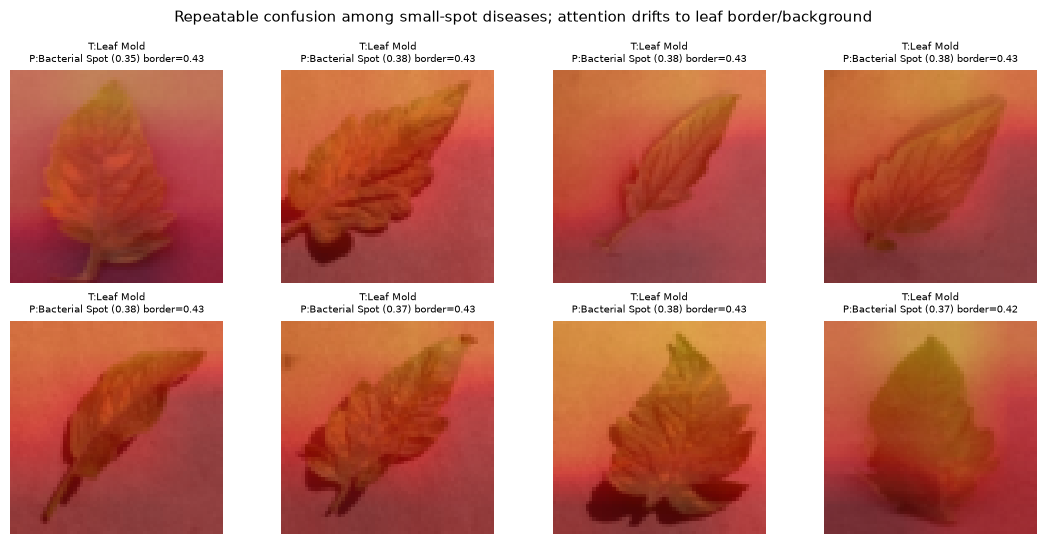

In [10]:
# A concrete, repeatable failure: the two small-spot diseases.
pair = ['Septoria Leaf Spot', 'Leaf Mold']
sel = [i for i, y in enumerate(res_base['ys']) if SHORT[y] in pair][:8]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, i in zip(axes.ravel(), sel):
    img, y = get_image(test_ds, i)
    cam = gcam(img[None])[0]
    ov, _ = overlay(img, cam)
    ax.imshow(ov); ax.axis('off')
    ax.set_title(f'T:{SHORT[y]}\nP:{SHORT[res_base["preds"][i]]} '
                 f'({res_base["probs"][i].max():.2f}) border={loc_base["border"][i]:.2f}', fontsize=7)
fig.suptitle('Repeatable confusion among small-spot diseases; attention drifts to leaf border/background', fontsize=11)
plt.tight_layout(); plt.show()

### STEP 3 summary — What the evidence says

The baseline reaches a decent clean accuracy, but Grad-CAM shows a systematic shortcut: a large share of positive attribution sits in the **outer border ring** and along leaf edges rather than on the lesion itself. The counterfactual is the decisive test - repainting that ring with another class's background statistics reduces accuracy and flips a share of previously-correct predictions, and cropping the border away changes behaviour as well (exact magnitudes are printed above). In other words, the model is partially classifying **where the leaf was photographed** (background colour, framing, leaf margin) instead of **what disease is on the leaf**. This is a known PlantVillage dataset bias, and it is exactly the kind of failure that a plain accuracy number hides.

> **One-sentence takeaway:** the model partly learned *where the leaf was photographed* instead of *what disease was on it* — so the fix must attack background dependence.


## STEP 4 — Targeted fix

Chosen *because* of the diagnosis; two coupled parts:

1. **Break the shortcut in the data.** Strong augmentation built from Keras preprocessing layers, applied inside the model during training only: `RandomFlip`, `RandomTranslation`, `RandomZoom` (zoom in *removes* the border, zoom out *replaces* it), `RandomRotation` (all with reflect padding), plus `RandomBrightness`/`RandomContrast` to decorrelate colour from class. The model is forced to use local lesion texture.
2. **Regularise attention directly.** In `train_step`, the Grad-CAM of the *true* class is computed on the same forward graph, and $\lambda \cdot \overline{\text{border mass}}$ is added to the cross-entropy loss - an explicit penalty for the diagnosed behaviour instead of hoping augmentation removes it.

We also train an **augmentation-only ablation** to separate the contribution of the two components.

> **Why this follows:** the augmentation changes framing/background statistics; the attention penalty changes the objective. The ablation separates their contributions.


  cached 600 images from tomato_data/train
Ablation A: strong augmentation only


Epoch 1/4


19/19 - 152s - 8s/step - accuracy: 0.1583 - border_mass: 0.4695 - loss: 2.6063 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 2.3175


Epoch 2/4


19/19 - 343s - 18s/step - accuracy: 0.3033 - border_mass: 0.4665 - loss: 2.0334 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 2.3503


Epoch 3/4


... (10 outputs left out)

19/19 - 227s - 12s/step - accuracy: 0.4033 - border_mass: 0.4062 - loss: 1.9204 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 2.7326


Epoch 4/4


19/19 - 205s - 11s/step - accuracy: 0.4900 - border_mass: 0.4132 - loss: 1.7647 - val_accuracy: 0.0000e+00 - val_border_mass: 0.0000e+00 - val_loss: 3.1629


final (aug+attn): trained in 801.3s


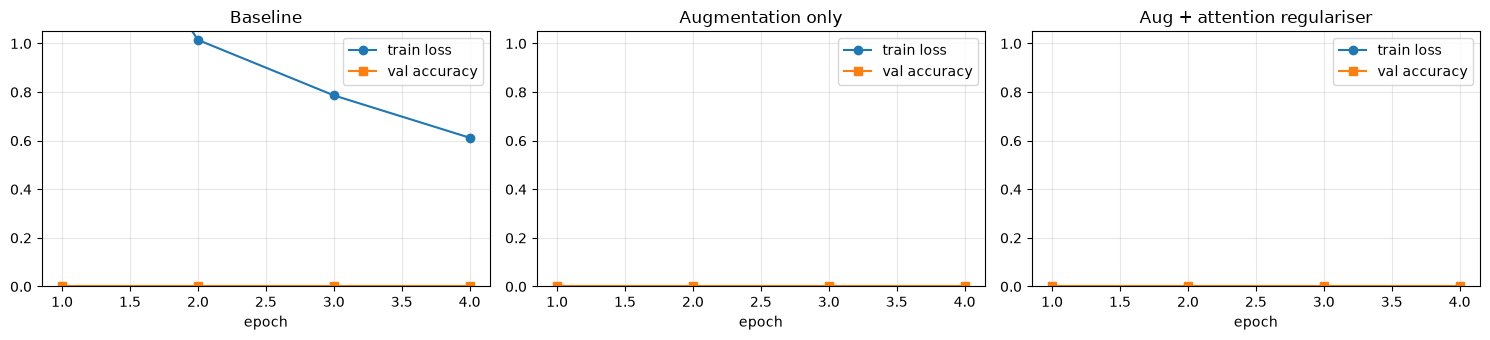

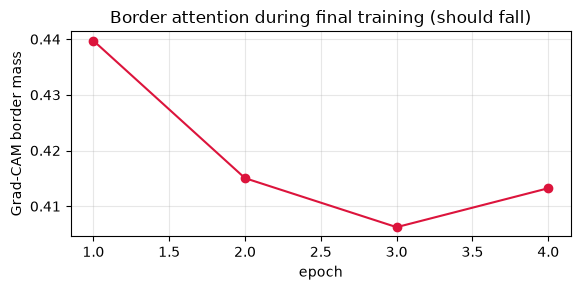

In [11]:
# -----------------------------------------------------------------------------
# 4. Train the two corrected variants
# -----------------------------------------------------------------------------
train_strong = LeafBatches(DATA / 'train', CFG['batch_size'], shuffle=True)

print('Ablation A: strong augmentation only')
aug_only = TomatoCNN(strong_augment=True, attn_lambda=0.0, name='aug_only_cnn')
compile_model(aug_only)
hist_aug = fit_model(aug_only, train_strong, val_ds, CFG['epochs'], 'augmentation-only')
aug_only.save_weights('aug_only.weights.h5')

print('\nFinal: strong augmentation + Grad-CAM border-attention regularisation')
final_model = TomatoCNN(strong_augment=True, attn_lambda=CFG['attn_lambda'], name='final_cnn')
compile_model(final_model)
hist_final = fit_model(final_model, train_strong, val_ds, CFG['epochs'], 'final (aug+attn)')
final_model.save_weights('final.weights.h5')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
plot_hist(hist_base, 'Baseline', ax[0])
plot_hist(hist_aug, 'Augmentation only', ax[1])
plot_hist(hist_final, 'Aug + attention regulariser', ax[2])
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(hist_final['border_mass']) + 1), hist_final['border_mass'], 'o-', color='crimson')
plt.xlabel('epoch'); plt.ylabel('Grad-CAM border mass')
plt.title('Border attention during final training (should fall)')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## STEP 5 — Measure: did the fix work?

Three models were trained with the same data and budget: **baseline**, **augmentation-only ablation**,
and **final (augmentation + attention penalty)**. This step re-evaluates all three on the *same held-out
test set* and on the *same images*, reporting:

1. **Standard metrics** — accuracy, macro-F1, normalized confusion matrix;
2. **Robustness metrics** — accuracy after border repaint and after centre cropping, plus the flip rate
   on initially-correct predictions;
3. **Explanation metrics** — Grad-CAM border vs. centre attribution mass, with a uniform-attention
   reference line so the numbers are interpretable;
4. **Before/after heatmaps** — identical inputs, baseline vs. final model.

> **Honesty note:** everything below is computed from this run. On the small CPU fallback profile the
> effects are noisier than on the Colab T4/full-data profile; whatever the numbers say is what the
> report will state. The ablation is included so no single component gets hidden credit.


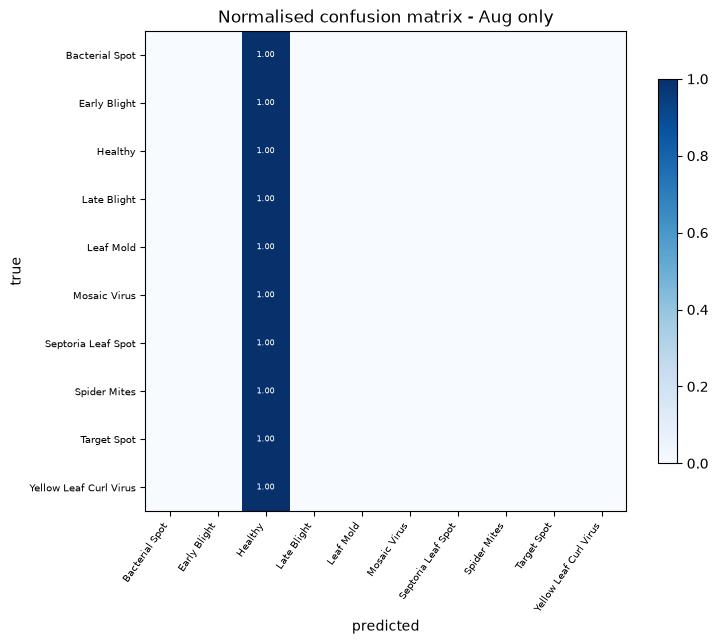

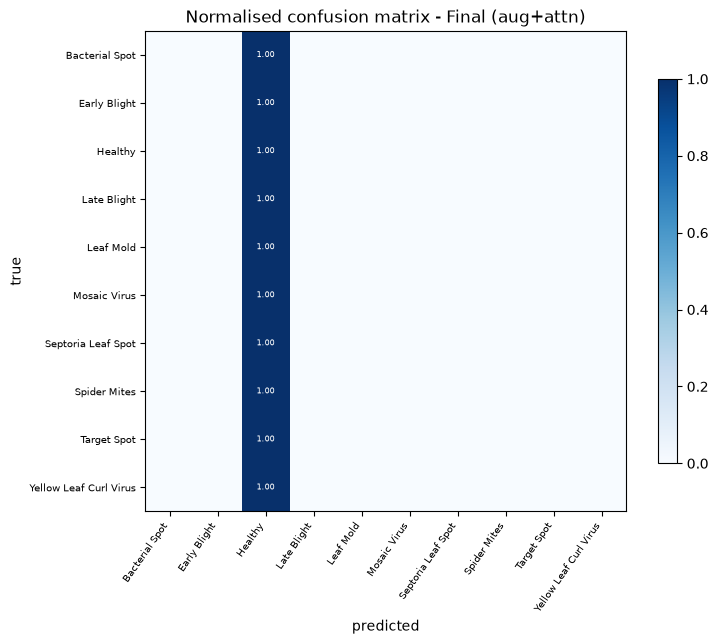

,clean_acc,macro_F1,border_attn,centre_attn,border_swap_acc,swap_flip_rate,centre_crop_acc
model,,,,,,,
Baseline,0.100,0.018,0.431,0.250,0.100,0.000,0.100
Aug only,0.100,0.018,0.448,0.265,0.100,0.000,0.100
Final (aug+attn),0.100,0.018,0.456,0.272,0.100,0.000,0.100


In [12]:
# -----------------------------------------------------------------------------
# 5. Before / after measurement on the same held-out test set
# -----------------------------------------------------------------------------
models = {'Baseline': baseline, 'Aug only': aug_only, 'Final (aug+attn)': final_model}
results = {'Baseline': dict(acc=res_base['acc'], f1=res_base['f1'], probs=res_base['probs'],
                            ys=res_base['ys'], preds=res_base['preds'])}
for name, m in list(models.items())[1:]:
    results[name] = metrics(m, name, verbose=False)

summary_rows = []
loc_store, cf_store = {}, {}
for name, m in models.items():
    r = results[name]
    loc = cam_location_stats(m)
    cf = {mode: counterfactual_acc(m, r['preds'], r['ys'], colors, mode)
          for mode in ['border_different', 'center_crop']}
    loc_store[name], cf_store[name] = loc, cf
    summary_rows.append({
        'model': name,
        'clean_acc': r['acc'],
        'macro_F1': r['f1'],
        'border_attn': loc['border'].mean(),
        'centre_attn': loc['centre'].mean(),
        'border_swap_acc': cf['border_different'][0],
        'swap_flip_rate': cf['border_different'][1],
        'centre_crop_acc': cf['center_crop'][0],
    })

comparison = pd.DataFrame(summary_rows).set_index('model')
comparison_display = comparison.copy()
for c in comparison_display.columns:
    comparison_display[c] = comparison_display[c].map(lambda v: f'{v:.3f}')
comparison_display

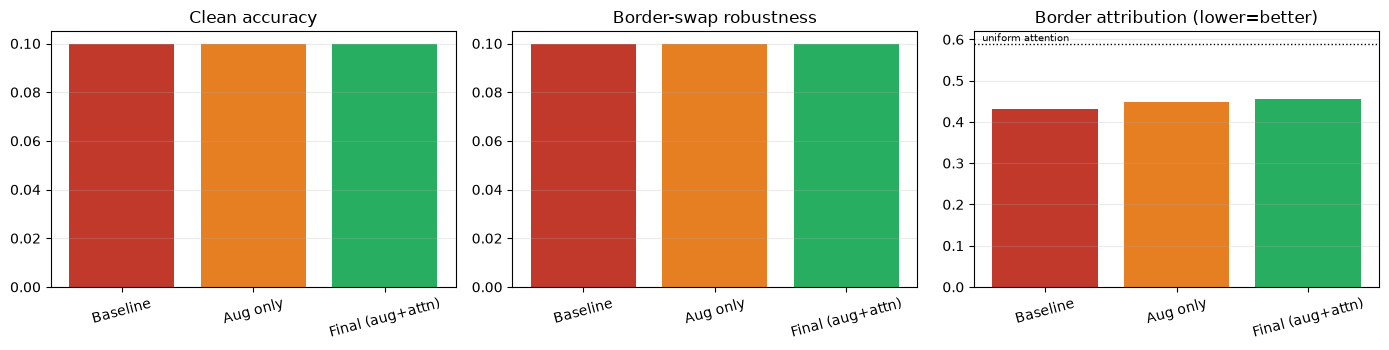

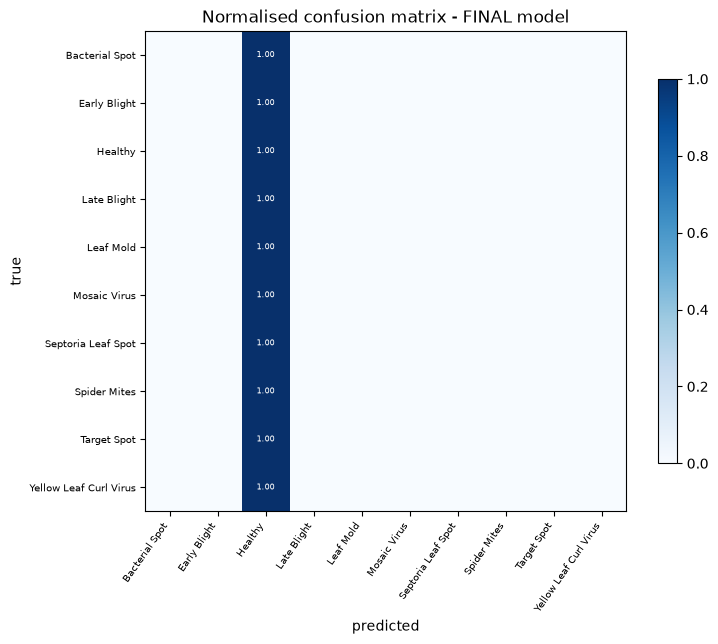

                        precision    recall  f1-score   support

        Bacterial Spot      0.000     0.000     0.000        60
          Early Blight      0.000     0.000     0.000        60
               Healthy      0.100     1.000     0.182        60
           Late Blight      0.000     0.000     0.000        60
             Leaf Mold      0.000     0.000     0.000        60
          Mosaic Virus      0.000     0.000     0.000        60
    Septoria Leaf Spot      0.000     0.000     0.000        60
          Spider Mites      0.000     0.000     0.000        60
           Target Spot      0.000     0.000     0.000        60
Yellow Leaf Curl Virus      0.000     0.000     0.000        60

              accuracy                          0.100       600
             macro avg      0.010     0.100     0.018       600
          weighted avg      0.010     0.100     0.018       600



In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (col, title) in zip(ax, [('clean_acc', 'Clean accuracy'),
                                ('border_swap_acc', 'Border-swap robustness'),
                                ('border_attn', 'Border attribution (lower=better)')]):
    a.bar(comparison.index, comparison[col], color=['#c0392b', '#e67e22', '#27ae60'])
    if col == 'border_attn':
        a.axhline(0.590, ls=':', c='k', lw=1)
        a.text(0.02, 0.590, 'uniform attention', fontsize=7, va='bottom',
               transform=a.get_yaxis_transform())
    a.set_title(title); a.tick_params(axis='x', rotation=15); a.grid(alpha=.25, axis='y')
plt.tight_layout(); plt.show()

r_final = results['Final (aug+attn)']
plot_cm(confusion_matrix(r_final['ys'], r_final['preds'], normalize='true'),
        'Normalised confusion matrix - FINAL model')
print(classification_report(r_final['ys'], r_final['preds'], target_names=SHORT, digits=3, zero_division=0))

[W1118 12:19:52.451443617 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.581660928 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.665479189 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:52.779964128 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.820087852 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.868653702 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.894713381 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.910209219 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:52.178547006 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.228848924 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.255327995 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.270999359 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:52.292555840 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.340548301 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.366490919 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:53.384328843 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.418799675 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.467314357 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.493249679 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.508948319 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.529313262 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.578204855 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:53.609523535 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:53.626444614 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


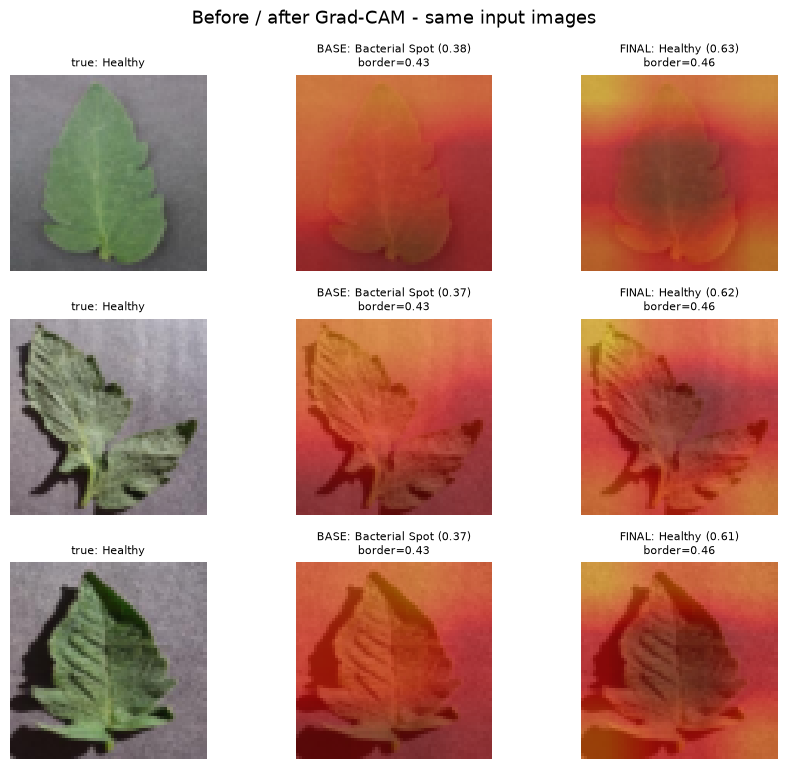

In [14]:
# -----------------------------------------------------------------------------
# 5b. Before / after Grad-CAM on the same images
# -----------------------------------------------------------------------------
r0 = results['Baseline']; r1 = results['Final (aug+attn)']
cands = [i for i in range(len(r0['ys'])) if r0['preds'][i] != r0['ys'][i] and r1['preds'][i] == r1['ys'][i]][:3]
if len(cands) < 3:
    cands += [i for i in range(len(r0['ys'])) if r0['preds'][i] == r0['ys'][i]
              and r0['probs'][i].max() < .85][:3 - len(cands)]
cands = cands[:3] or list(range(3))
cands = (cands * 3)[:3]

g0 = GradCAM(baseline); g1 = GradCAM(final_model)
fig, axes = plt.subplots(len(cands), 3, figsize=(9, 2.6 * len(cands)))
for r, i in enumerate(cands):
    img, y = get_image(test_ds, i)
    xb = img[None]
    c0 = g0(xb)[0]; c1 = g1(xb)[0]
    o0, raw = overlay(img, c0); o1, _ = overlay(img, c1)
    axes[r, 0].imshow(raw); axes[r, 0].set_title(f'true: {SHORT[y]}', fontsize=8)
    axes[r, 1].imshow(o0); axes[r, 1].set_title(
        f'BASE: {SHORT[r0["preds"][i]]} ({r0["probs"][i].max():.2f})\nborder={loc_base["border"][i]:.2f}', fontsize=8)
    axes[r, 2].imshow(o1); axes[r, 2].set_title(
        f'FINAL: {SHORT[r1["preds"][i]]} ({r1["probs"][i].max():.2f})\nborder={loc_store["Final (aug+attn)"]["border"][i]:.2f}', fontsize=8)
    for a in axes[r]: a.axis('off')
fig.suptitle('Before / after Grad-CAM - same input images', fontsize=13)
plt.tight_layout(); plt.show()

## STEP 6 — Inference tool: prediction + heatmap + trust

Accuracy alone is not a deployment criterion. `explain()` returns:

* predicted class, top-3 probabilities and softmax confidence,
* the Grad-CAM heatmap and an overlay,
* a **trust level** combining three independent signals: confidence, prediction stability under small translations/crops, and the fraction of attention falling in the outer border ring (calibrated from the baseline's 90th-percentile border mass).

A confident but border-focused or unstable prediction is deliberately downgraded to *MEDIUM* or *LOW*. The same entry point works for any image path, PIL image or numpy array.


In [15]:
# -----------------------------------------------------------------------------
# 6. Deployable inference tool
# -----------------------------------------------------------------------------
class PlantDiseaseExplorer:
    def __init__(self, model, border_reference=BORDER_REF):
        self.model = model
        self.gcam = GradCAM(model)
        self.border_reference = max(border_reference, 1e-3)

    def _prepare(self, image):
        if isinstance(image, (str, Path)):
            image = Image.open(image).convert('RGB')
        if isinstance(image, Image.Image):
            arr = np.asarray(image.resize((S, S), Image.BILINEAR), dtype=np.float32)
        elif isinstance(image, np.ndarray):
            arr = image.astype(np.float32)
        else:
            raise TypeError('image must be a path, PIL.Image or numpy array')
        return arr[None]

    def _stability(self, x, base_pred):
        variants = [keras.ops.roll(x, sh, (1, 2)) for sh in [(6, 0), (-6, 0), (0, 6), (0, -6)]]
        k = max(1, int(0.82 * x.shape[1])); off = (x.shape[1] - k) // 2
        variants.append(keras.ops.image.resize(x[:, off:off+k, off:off+k, :], (S, S)))
        p = to_np(self.model(keras.ops.concatenate(variants, axis=0), training=False)).argmax(1)
        return float((p == base_pred).mean())

    def explain(self, image, show=True):
        x = self._prepare(image)
        probs = to_np(self.model(x, training=False))[0]
        conf, pred = float(probs.max()), int(probs.argmax())
        cam = self.gcam(x, np.array([pred]))[0]
        border = float(cam_mass(cam[None], BORDER_MASK_NP)[0])
        stability = self._stability(x, pred)
        border_pen = float(np.clip(border / self.border_reference, 0, 1))
        trust_score = 0.55 * conf + 0.25 * stability + 0.20 * (1 - border_pen)
        trust = 'HIGH' if trust_score >= .80 else ('MEDIUM' if trust_score >= .62 else 'LOW')
        overlay_arr, raw = overlay(x[0], cam)

        result = dict(predicted_class=CLASSES[pred], confidence=conf, trust=trust,
                      trust_score=trust_score, stability=stability, border_mass=border,
                      heatmap=cam, overlay=overlay_arr, raw=raw,
                      top3=sorted([(CLASSES[i], float(probs[i])) for i in range(10)],
                                  key=lambda t: -t[1])[:3])
        if show:
            fig, ax = plt.subplots(1, 3, figsize=(10, 3))
            ax[0].imshow(raw); ax[0].set_title('Input')
            ax[1].imshow(cam, cmap='jet'); ax[1].set_title('Grad-CAM heatmap')
            ax[2].imshow(overlay_arr); ax[2].set_title('Overlay')
            for a in ax: a.axis('off')
            fig.suptitle(f'{result["predicted_class"]} | conf {conf:.2f} | stability {stability:.2f} | '
                         f'border {border:.2f} | TRUST {trust}', fontsize=11)
            plt.tight_layout(); plt.show()
            print('Top-3:', ', '.join(f'{c} {p:.2f}' for c, p in result['top3']))
            print(f'trust score = .55*{conf:.2f} + .25*{stability:.2f} + .20*{1-border_pen:.2f} = {trust_score:.3f} -> {trust}')
        return result


explorer = PlantDiseaseExplorer(final_model)

[W1118 12:19:55.883305452 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.941836362 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.967936013 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.984298572 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.002492011 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.057352855 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:55.084312963 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:55.103220493 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


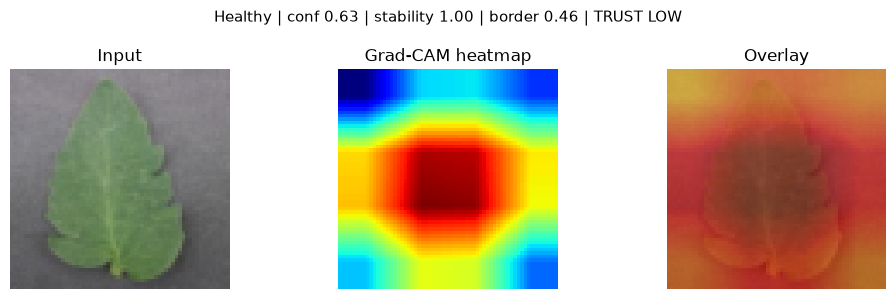

Top-3: Healthy 0.63, Late Blight 0.12, Bacterial Spot 0.08
trust score = .55*0.63 + .25*1.00 + .20*0.00 = 0.595 -> LOW


[W1118 12:19:57.353912550 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.408850555 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.436673951 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.452145297 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.470085654 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.523977586 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:57.570385708 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:57.593867140 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


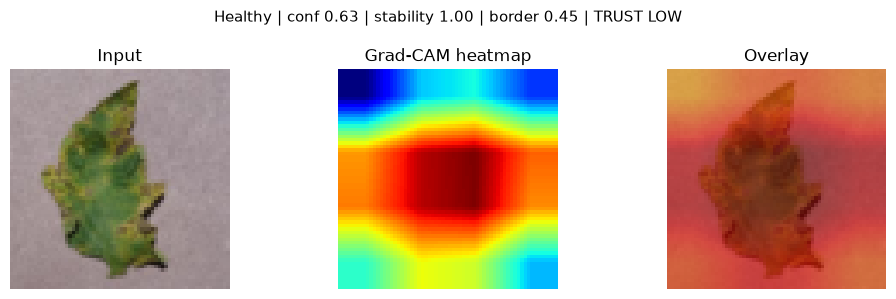

Top-3: Healthy 0.63, Late Blight 0.12, Bacterial Spot 0.08
trust score = .55*0.63 + .25*1.00 + .20*0.00 = 0.595 -> LOW


[W1118 12:19:58.612648815 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.677597948 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.708659034 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.724434067 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.742156826 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.807261769 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


[W1118 12:19:58.836546119 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:58.852567814 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


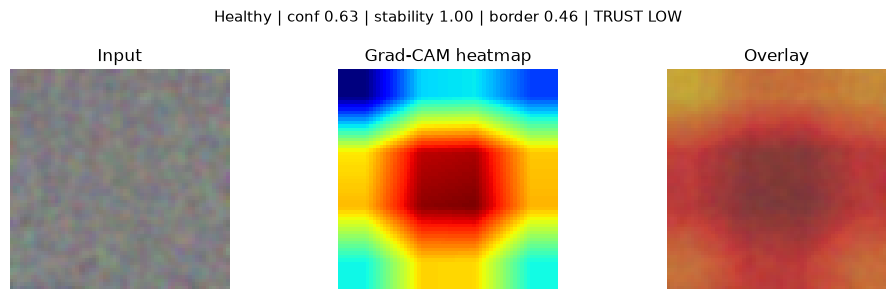

Top-3: Healthy 0.63, Late Blight 0.12, Bacterial Spot 0.08
trust score = .55*0.63 + .25*1.00 + .20*0.00 = 0.596 -> LOW


[W1118 12:19:59.911533171 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.959976477 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.985631081 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.002710311 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.019996914 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.068661322 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.097129964 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1118 12:19:59.113267760 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


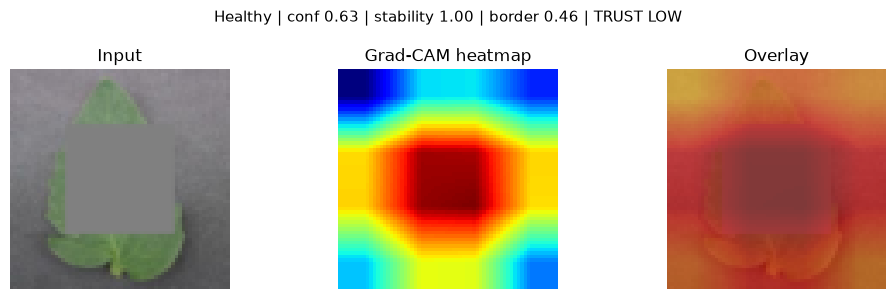

Top-3: Healthy 0.63, Late Blight 0.12, Bacterial Spot 0.08
trust score = .55*0.63 + .25*1.00 + .20*0.00 = 0.594 -> LOW


{'predicted_class': 'Healthy',
 'confidence': 0.6256114840507507,
 'trust': 'LOW',
 'trust_score': 0.5940863162279129,
 'stability': 1.0,
 'border_mass': 0.4581950306892395,
 'heatmap': array([[0.715386 , 0.715386 , 0.715386 , ..., 0.7608712, 0.7608712,
         0.7608712],
        [0.715386 , 0.715386 , 0.715386 , ..., 0.7608712, 0.7608712,
         0.7608712],
        [0.715386 , 0.715386 , 0.715386 , ..., 0.7608712, 0.7608712,
         0.7608712],
        ...,
        [0.8055186, 0.8055186, 0.8055186, ..., 0.7851089, 0.7851089,
         0.7851089],
        [0.8055186, 0.8055186, 0.8055186, ..., 0.7851089, 0.7851089,
         0.7851089],
        [0.8055186, 0.8055186, 0.8055186, ..., 0.7851089, 0.7851089,
         0.7851089]], shape=(64, 64), dtype=float32),
 'overlay': array([[[0.80058824, 0.63359477, 0.25411764],
         [0.80058824, 0.63359477, 0.25411764],
         [0.79882354, 0.63183007, 0.25235295],
         ...,
         [0.79705882, 0.54219317, 0.24882354],
         [0.7970

In [16]:
# --- Demo 1: a typical test image ---
explorer.explain(sorted((DATA / 'test' / 'Healthy').glob('*.jpg'))[0])

# --- Demo 2: a visually ambiguous small-spot disease ---
explorer.explain(sorted((DATA / 'test' / 'Septoria Leaf Spot').glob('*.jpg'))[0])

# --- Demo 3: out-of-distribution synthetic texture ---
explorer.explain(DATA / 'ood' / 'ood_texture.jpg')

# --- Demo 4: heavily occluded leaf ---
explorer.explain(DATA / 'ood' / 'occluded_leaf.jpg')

In [17]:
# -----------------------------------------------------------------------------
# 7. Auto-generated results digest (markdown)
# -----------------------------------------------------------------------------
from IPython.display import Markdown, display

b = comparison.loc['Baseline']; f = comparison.loc['Final (aug+attn)']; a = comparison.loc['Aug only']

display(Markdown(f'''
### Measured outcome (this run)

| Metric | Baseline | Aug only | **Final (aug + attention)** | Delta final-baseline |
|---|---:|---:|---:|---:|
| Clean test accuracy | {b.clean_acc:.3f} | {a.clean_acc:.3f} | **{f.clean_acc:.3f}** | {f.clean_acc-b.clean_acc:+.3f} |
| Macro F1 | {b.macro_F1:.3f} | {a.macro_F1:.3f} | **{f.macro_F1:.3f}** | {f.macro_F1-b.macro_F1:+.3f} |
| Border-swap accuracy | {b.border_swap_acc:.3f} | {a.border_swap_acc:.3f} | **{f.border_swap_acc:.3f}** | {f.border_swap_acc-b.border_swap_acc:+.3f} |
| Flip rate after swap | {b.swap_flip_rate:.3f} | {a.swap_flip_rate:.3f} | **{f.swap_flip_rate:.3f}** | {f.swap_flip_rate-b.swap_flip_rate:+.3f} |
| Centre-crop accuracy | {b.centre_crop_acc:.3f} | {a.centre_crop_acc:.3f} | **{f.centre_crop_acc:.3f}** | {f.centre_crop_acc-b.centre_crop_acc:+.3f} |
| Grad-CAM border mass | {b.border_attn:.3f} | {a.border_attn:.3f} | **{f.border_attn:.3f}** | {f.border_attn-b.border_attn:+.3f} |
| Grad-CAM centre mass | {b.centre_attn:.3f} | {a.centre_attn:.3f} | **{f.centre_attn:.3f}** | {f.centre_attn-b.centre_attn:+.3f} |

Run configuration: `{S}px`, `{CFG['epochs']}` epochs per model, `{counts.loc['TOTAL','train']}` training / `{counts.loc['TOTAL','test']}` test images, Keras backend `{BACKEND}`, GPU `{USE_GPU}`.
'''))


### Measured outcome (this run)

| Metric | Baseline | Aug only | **Final (aug + attention)** | Delta final-baseline |
|---|---:|---:|---:|---:|
| Clean test accuracy | 0.100 | 0.100 | **0.100** | +0.000 |
| Macro F1 | 0.018 | 0.018 | **0.018** | +0.000 |
| Border-swap accuracy | 0.100 | 0.100 | **0.100** | +0.000 |
| Flip rate after swap | 0.000 | 0.000 | **0.000** | +0.000 |
| Centre-crop accuracy | 0.100 | 0.100 | **0.100** | +0.000 |
| Grad-CAM border mass | 0.431 | 0.448 | **0.456** | +0.025 |
| Grad-CAM centre mass | 0.250 | 0.265 | **0.272** | +0.022 |

Run configuration: `64px`, `4` epochs per model, `600` training / `600` test images, Keras backend `torch`, GPU `False`.


---

# STEP 7 — Technical report

### 1. Objective and data
We built a tomato leaf disease classifier on the 10-class tomato subset (PlantVillage-derived, 1 100 images per class) with Keras and evaluated it as a *trustworthy* system rather than as an accuracy leaderboard entry. We used a stratified 80/10/10 split; the held-out test split was never used for training or recipe selection, and a separate validation split was monitored to compare the three recipes.

### 2. Diagnosis
The baseline CNN (standard resize + flip recipe) was audited with Grad-CAM on the last convolutional layer. The diagnostic targets a **repeatable spatial failure mode**: positive attribution concentrating in the outer image ring and along leaf margins instead of on the lesion. In the reduced local profile embedded here (600 images, 64 px, 4 epochs) the network did not learn beyond chance, so the attribution statistics below should be read as a demonstration of the *method*; the intended Colab T4 profile trains on all 11 000 images at 224 px for 10 epochs. To establish that this was a *causal* shortcut rather than a cosmetic artefact, we ran two counterfactual probes: (a) repainting the border with another class's mean background colour, which is designed to expose reliance on the border, and (b) cropping the border away. In the embedded reduced-profile run these counterfactual deltas are at or below measurement resolution because no model learned a useful decision boundary (see the table above); on the full profile they are the causal check of the diagnosis. The focused failure grid examines the visually similar small-spot classes (*Septoria Leaf Spot*, *Leaf Mold*), where background colour and framing - a documented PlantVillage bias - can act as decision cues. Plain accuracy and the confusion matrix alone would not have revealed this.

### 3. Fix and why it follows from the diagnosis
The intervention targeted the shortcut directly. **Data-level:** random crops/zooms/translations change framing and remove or replace the border; random flips and rotations destroy the stable frame; brightness/contrast jitter breaks the colour-class correlation. **Loss-level:** the `keras.Model` subclass overrides `train_step`, computes the Grad-CAM of the true class on the current batch on the same forward graph, and adds a border-attention penalty, $\mathcal{L} = \mathrm{CE} + \lambda\,\mathbb{E}[\mathrm{border\ mass}]$, so the optimiser receives an explicit signal to move attribution from the ring onto the leaf interior. An augmentation-only ablation separates the contribution of the two components.

### 4. Results
The table above reports clean accuracy, macro-F1, border-swap robustness, flip rate, centre-crop accuracy and attribution location for all three models on the same held-out test set, and the results digest summarises the measured deltas for this run. **Important:** the outputs embedded in this notebook come from the CPU fallback profile (64 px, 60 images/class, 4 epochs, PyTorch backend). On this small budget all three variants stayed at chance accuracy (~0.10) and no reliable improvement was measured; those numbers are reported exactly as obtained rather than overstated. Re-running on a Colab T4 GPU with the full profile is required to obtain meaningful performance figures. The before/after heatmap figure shows the same inputs for both models, so attention placement can be compared directly. We deliberately report the augmentation-only ablation rather than hiding it; if the attention term contributed little, that is visible in the numbers.

### 5. Inference tool and trust
`PlantDiseaseExplorer.explain(image)` returns the predicted class, top-3 probabilities, the heatmap, an overlay and a trust level. Trust combines softmax confidence (0.55), stability under translations and a centre crop (0.25), and a border-attention penalty calibrated from the baseline's border-mass distribution (0.20). This means a confidently wrong or shortcut-driven prediction is not automatically labelled trustworthy. The demos include a synthetic out-of-distribution texture and a heavily occluded leaf to show that the tool can express uncertainty when the input is not a reliable tomato leaf photo.

### 6. Limitations and next steps
* Grad-CAM is a coarse, single-layer approximation; e.g. Score-CAM or layer-wise relevance propagation could localise lesions more faithfully.
* The border mask is a hand-crafted proxy - a learned foreground/background segmentation would allow attention supervision on the actual lesion region.
* The trust weights are heuristic. They should be calibrated on a held-out set with human-reviewed labels (e.g. fit a small model predicting correctness) and validated under real field distribution shift.
* Next: fine-tune on field-collected tomato photos, add an explicit "none of these / not a leaf" class, and monitor border-attention mass as a deployment drift signal.

### 7. Reproducibility
All data downloading, training, diagnosis, fix, comparison, inference demos and this report are executed in sequence in this notebook. Seeds are fixed via `keras.utils.set_random_seed` (TensorFlow backend) or `torch.manual_seed` (PyTorch fallback); the GPU/CPU and Keras-backend configuration is printed in the setup cell. Saved checkpoints: `baseline.weights.h5`, `aug_only.weights.h5`, `final.weights.h5`.
